Natural gas price analysis and forecasting

In [2]:
# Natural Gas Pricing: Trend + Monthly Seasonality + Daily Interpolation + 12M Forecast
# Requirements: pandas, numpy, matplotlib, scipy
# You can paste the CSV path or raw CSV string into `CSV_SOURCE`.

import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from datetime import datetime, timedelta

1) Load and clean data

In [3]:
CSV_SOURCE = """Dates,Prices
10/31/20,1.01E+01
11/30/20,1.03E+01
12/31/20,1.10E+01
1/31/21,1.09E+01
2/28/21,1.09E+01
3/31/21,1.09E+01
4/30/21,1.04E+01
5/31/21,9.84E+00
6/30/21,1.00E+01
7/31/21,1.01E+01
8/31/21,1.03E+01
9/30/21,1.02E+01
10/31/21,1.01E+01
11/30/21,1.12E+01
12/31/21,1.14E+01
1/31/22,1.15E+01
2/28/22,1.18E+01
3/31/22,1.15E+01
4/30/22,1.07E+01
5/31/22,1.07E+01
6/30/22,1.04E+01
7/31/22,1.05E+01
8/31/22,1.04E+01
9/30/22,1.08E+01
10/31/22,1.10E+01
11/30/22,1.16E+01
12/31/22,1.16E+01
1/31/23,1.21E+01
2/28/23,1.17E+01
3/31/23,1.20E+01
4/30/23,1.15E+01
5/31/23,1.12E+01
6/30/23,1.09E+01
7/31/23,1.14E+01
8/31/23,1.11E+01
9/30/23,1.15E+01
10/31/23,1.18E+01
11/30/23,1.22E+01
12/31/23,1.28E+01
1/31/24,1.26E+01
2/29/24,1.24E+01
3/31/24,1.27E+01
4/30/24,1.21E+01
5/31/24,1.14E+01
6/30/24,1.15E+01
7/31/24,1.16E+01
8/31/24,1.15E+01
9/30/24,1.18E+01
"""

In [4]:
def load_monthly_prices(csv_source: str) -> pd.DataFrame:
    df = pd.read_csv(io.StringIO(csv_source))
    # Parse dates (US-style month/day/year) assuming 20xx (CSV provides 2-digit years)
    df['Date'] = pd.to_datetime(df['Dates'])
    # Convert scientific notation strings to floats
    df['Price'] = df['Prices'].astype(float)
    df = df[['Date', 'Price']].sort_values('Date').reset_index(drop=True)
    return df

monthly_df = load_monthly_prices(CSV_SOURCE)

C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_14444\1261513798.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Dates'])


2) Fit linear trend

In [5]:
# Time index in days from first observation
t0 = monthly_df['Date'].min()
monthly_df['t_days'] = (monthly_df['Date'] - t0).dt.days.astype(float)

# Linear regression (least squares) for trend: price = a + b * t
X = np.vstack([np.ones(len(monthly_df)), monthly_df['t_days'].values]).T
y = monthly_df['Price'].values
coeffs = np.linalg.lstsq(X, y, rcond=None)[0]
a, b = coeffs[0], coeffs[1]
monthly_df['Trend'] = a + b * monthly_df['t_days']

3) Compute calendar-month seasonality (mean residual per month)

In [6]:
monthly_df['Month'] = monthly_df['Date'].dt.month
monthly_df['Residual'] = monthly_df['Price'] - monthly_df['Trend']

seasonal_means = monthly_df.groupby('Month')['Residual'].mean()
# Normalize to zero mean to avoid double-counting level
seasonal_means = seasonal_means - seasonal_means.mean()

# Build a mapping month -> seasonal adjustment
seasonal_map = {int(m): float(v) for m, v in seasonal_means.items()}

# Add fitted seasonal to existing months
monthly_df['Seasonal'] = monthly_df['Month'].map(seasonal_map)
monthly_df['Fitted'] = monthly_df['Trend'] + monthly_df['Seasonal']

4) Forecast next 12 months (month-end), add seasonality

In [7]:
def next_month_end(date: pd.Timestamp) -> pd.Timestamp:
    # Move to first day of next month, then find month-end
    first_next = (date + pd.offsets.MonthBegin(1)).normalize()
    return (first_next + pd.offsets.MonthEnd(0))

last_date = monthly_df['Date'].max()
forecast_dates = []
d = last_date
for _ in range(12):
    d = next_month_end(d)  # next month-end
    forecast_dates.append(d)

In [8]:
# Compute time indices for future dates
t_future = np.array([(fd - t0).days for fd in forecast_dates], dtype=float)
trend_future = a + b * t_future
seasonal_future = np.array([seasonal_map[int(fd.month)] for fd in forecast_dates], dtype=float)
price_future = trend_future + seasonal_future

forecast_df = pd.DataFrame({
    'Date': forecast_dates,
    'Price_Forecast': price_future,
    'Trend': trend_future,
    'Seasonal': seasonal_future
})

 5) Build a daily interpolator over month-end observations (actual + forecast)

In [9]:
# Use month-end points to create a smooth daily curve with spline
obs_dates = pd.concat([monthly_df[['Date', 'Price']], 
                       forecast_df[['Date', 'Price_Forecast']].rename(columns={'Price_Forecast':'Price'})],
                      ignore_index=True).sort_values('Date')

# Ensure strictly increasing time vector for spline
t_all = (obs_dates['Date'] - t0).dt.days.astype(float).values
p_all = obs_dates['Price'].values

# Cubic spline over time
spline = CubicSpline(t_all, p_all, bc_type='natural')

def estimate_price(input_date) -> float:
    """
    Estimate the price at any date (historical or within the 12-month forecast horizon).
    input_date: str 'YYYY-MM-DD' or datetime-like
    Returns: float price estimate
    """
    if isinstance(input_date, str):
        dt = pd.to_datetime(input_date)
    elif isinstance(input_date, (pd.Timestamp, datetime)):
        dt = pd.Timestamp(input_date)
    else:
        raise ValueError("input_date must be a date-like or ISO date string.")

    t = (dt - t0).days
    # Guard: allow a small margin beyond forecast by clamping to spline domain
    t_min, t_max = t_all.min(), t_all.max()
    if t < t_min:
        # Extrapolate linearly using trend + calendar month seasonal
        trend_val = a + b * t
        seasonal_val = seasonal_map[int(dt.month)]
        return float(trend_val + seasonal_val)
    elif t > t_max:
        # Extrapolate using trend + calendar month seasonal
        trend_val = a + b * t
        seasonal_val = seasonal_map[int(dt.month)]
        return float(trend_val + seasonal_val)
    else:
        return float(spline(t))

6) Visualization

In [10]:
def plot_all():
    fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

    # Panel 1: Actuals, fitted, and forecast
    axes[0].plot(monthly_df['Date'], monthly_df['Price'], 'o-', label='Actual monthly', alpha=0.8)
    axes[0].plot(monthly_df['Date'], monthly_df['Fitted'], '--', label='Fitted (trend + seasonality)', alpha=0.8)
    axes[0].plot(forecast_df['Date'], forecast_df['Price_Forecast'], 'o--', label='Forecast 12M', alpha=0.8, color='tab:orange')
    axes[0].set_title('Monthly natural gas price: actual, fitted, and 12M forecast')
    axes[0].set_ylabel('Price')
    axes[0].legend()

    # Panel 2: Trend
    axes[1].plot(monthly_df['Date'], monthly_df['Trend'], label='Trend (linear)', color='tab:green')
    axes[1].set_title('Estimated trend')
    axes[1].set_ylabel('Price')
    axes[1].legend()

    # Panel 3: Seasonal by calendar month
    months = np.arange(1, 13)
    season_vals = [seasonal_map.get(int(m), np.nan) for m in months]
    axes[2].bar(months, season_vals, color='tab:purple', alpha=0.7)
    axes[2].set_title('Seasonal component by calendar month (mean residual, normalized)')
    axes[2].set_xlabel('Month')
    axes[2].set_ylabel('Seasonal adjustment')

    plt.tight_layout()
    plt.show()

In [11]:
# Example usage
## Example 1
print(estimate_price('2023-07-15'))

11.150044533076992


In [12]:
## Example 2
print(estimate_price('2025-05-31'))  # within the 12M forecast horizon

11.956127689067777


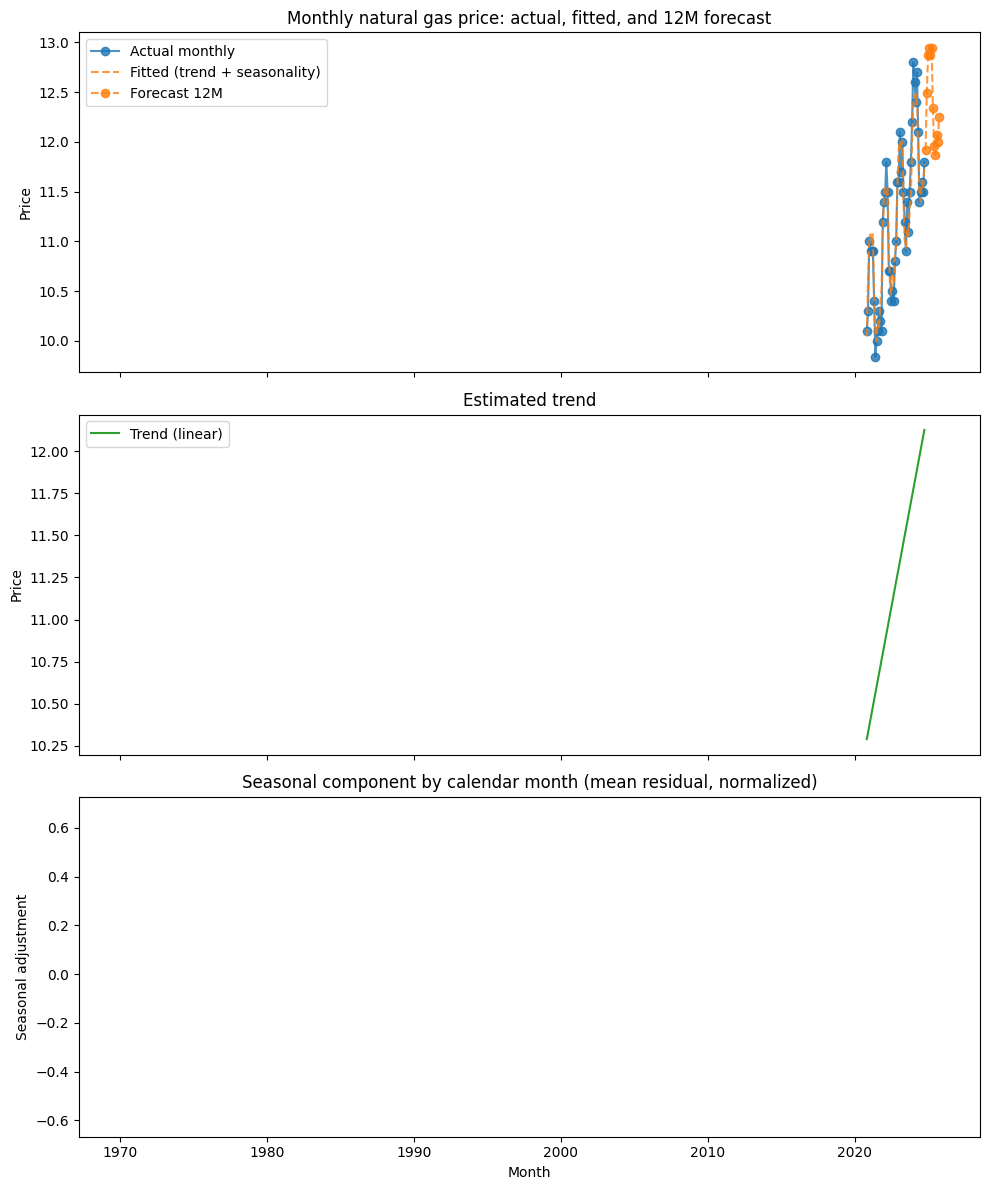

In [13]:
plot_all()